# Notebook 66 — CLIP embeddings and contrastive alignment

CLIP (Contrastive Language–Image Pre-training) learns a shared embedding space for images and text. An image encoder and a text encoder produce vectors of the same width, and matching image–text pairs are trained to have high similarity.

This notebook isolates the central mathematics with small vectors. We optimize embeddings directly rather than training large image and text encoders, keeping the focus on what the CLIP objective does.

Related material:

- [Notebook 51 — Contrastive learning and InfoNCE](51_contrastive_learning_and_infonce.ipynb)
- [Notebook 62 — Captioning comparison](62_recurrent_and_transformer_captioning_comparison.ipynb)
- [Foundation models for vision and language](../notes/16-vision-language/foundation-models-for-vision-and-language.md)
- [CLIP and contrastive image–text learning](../notes/16-vision-language/clip-and-contrastive-image-text-learning.md)

## Learning goals

- normalize image and text embeddings;
- construct and interpret an image–text similarity matrix;
- calculate image-to-text and text-to-image losses;
- understand temperature and bidirectional retrieval;
- identify assumptions and limitations of the batch objective.

In [13]:
from __future__ import annotations

import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ITEM_NAMES = ("dog", "cat", "airplane", "car", "tree", "flower")

## 1. A paired batch

Suppose a batch contains $N$ images and $N$ captions. Image $i$ and caption $i$ describe the same item. The encoders produce

$$
I\in\mathbb{R}^{N\times D},
\qquad
T\in\mathbb{R}^{N\times D}.
$$

The encoders may have different architectures, but their output widths must both equal $D$ so their vectors can be compared. We start with deliberately imperfect vectors: corresponding image and text rows are related, but noise prevents exact matches.

### Exercise 1 — Inspect the dimensions

Complete the expected shapes and create the positive-pair indices.

In [16]:
NUMBER_ITEMS = len(ITEM_NAMES)
EMBEDDING_DIM = 4

base_semantics = torch.tensor([
    [1.0, 0.8, 0.0, 0.1],   # dog
    [1.0, 0.6, 0.0, 0.2],   # cat
    [0.0, 0.1, 1.0, 0.8],   # airplane
    [0.0, 0.2, 1.0, 0.5],   # car
    [0.2, 1.0, 0.0, 0.7],   # tree
    [0.3, 1.0, 0.0, 0.4],   # flower
])
image_embeddings_raw = base_semantics + 0.18 * torch.randn_like(base_semantics)
text_embeddings_raw = base_semantics + 0.18 * torch.randn_like(base_semantics)

# complete the expected shapes.
assert image_embeddings_raw.shape == (NUMBER_ITEMS, EMBEDDING_DIM)
assert text_embeddings_raw.shape == (NUMBER_ITEMS, EMBEDDING_DIM)

# Positive pairs use matching row indices: 0 with 0, 1 with 1, etc.
positive_indices = torch.arange(NUMBER_ITEMS)
assert positive_indices.shape == (NUMBER_ITEMS,)
torch.testing.assert_close(positive_indices, torch.arange(NUMBER_ITEMS))

## 2. Normalize before comparison

A dot product depends on direction and length. CLIP removes the length effect by L2-normalizing every embedding:

$$
\hat v_i=\frac{v_i}{\lVert v_i\rVert_2}.
$$

Every normalized row has length one, so its dot product with another normalized vector is cosine similarity in the interval $[-1,1]$.

### Exercise 2 — Normalize every row

Use F.normalize along the embedding dimension, not across the batch.

In [17]:
# normalize every image and text row along its feature dimension.
image_embeddings = torch.nn.functional.normalize(image_embeddings_raw, dim=1)
text_embeddings = torch.nn.functional.normalize(text_embeddings_raw, dim=1)

torch.testing.assert_close(image_embeddings.norm(dim=1), torch.ones(NUMBER_ITEMS))
torch.testing.assert_close(text_embeddings.norm(dim=1), torch.ones(NUMBER_ITEMS))
print("raw image-vector lengths:       ", image_embeddings_raw.norm(dim=1))
print("normalized image-vector lengths:", image_embeddings.norm(dim=1))

raw image-vector lengths:        tensor([1.0686, 1.1517, 1.0665, 0.9660, 1.2005, 1.1234])
normalized image-vector lengths: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


## 3. One matrix compares every image with every text

$$
S=\hat I\hat T^T,
\qquad S\in\mathbb{R}^{N\times N}.
$$

- Row $i$: image $i$ compared with every caption.
- Column $j$: caption $j$ compared with every image.
- Cell $S_{ij}$: similarity between image $i$ and caption $j$.
- Diagonal $S_{ii}$: the known matching pairs.

A row is not one embedding; it contains $N$ comparison scores for one image.

For a longer conceptual summary, see [CLIP and contrastive image–text learning](../notes/16-vision-language/clip-and-contrastive-image-text-learning.md).

### Exercise 3 — Construct and visualize the similarity matrix

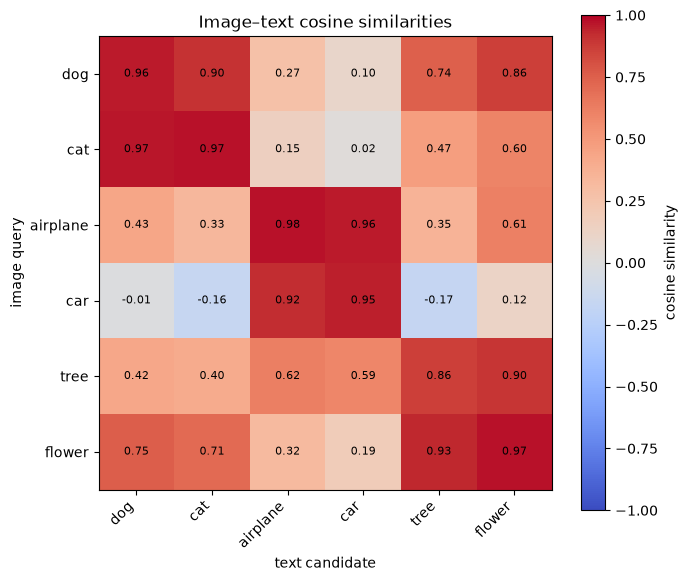

In [18]:
# compare every normalized image row with every normalized text row.
similarities = image_embeddings @ text_embeddings.T
assert similarities.shape == (NUMBER_ITEMS, NUMBER_ITEMS)
assert torch.all(similarities <= 1.0 + 1e-6)
assert torch.all(similarities >= -1.0 - 1e-6)

fig, axis = plt.subplots(figsize=(7, 6))
image = axis.imshow(similarities.numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(NUMBER_ITEMS), ITEM_NAMES, rotation=45, ha="right")
axis.set_yticks(range(NUMBER_ITEMS), ITEM_NAMES)
axis.set(xlabel="text candidate", ylabel="image query", title="Image–text cosine similarities")
for row in range(NUMBER_ITEMS):
    for column in range(NUMBER_ITEMS):
        axis.text(column, row, f"{similarities[row, column]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axis, label="cosine similarity")
plt.tight_layout()
plt.show()

## 4. Image-to-text contrastive loss

Treat every row as an $N$-class classification problem. Given image $i$, the correct text class is $i$; the other captions act as negatives.

$$
L_{image\rightarrow text}
=\frac{1}{N}\sum_{i=1}^{N}
-\log
\frac{\exp(S_{ii}/\tau)}
{\sum_{j=1}^{N}\exp(S_{ij}/\tau)}.
$$

Similarity becomes a logit after division by positive temperature $\tau$. F.cross_entropy performs the stable row-wise log-softmax and correct-target selection internally.

### Exercise 4 — Calculate the image-to-text loss

In [19]:
TEMPERATURE = 0.1

# scale similarities into logits and calculate row-wise cross-entropy.
image_to_text_logits = torch.div(similarities, TEMPERATURE)
image_to_text_loss = torch.nn.functional.cross_entropy(image_to_text_logits, positive_indices)

assert image_to_text_logits.shape == (NUMBER_ITEMS, NUMBER_ITEMS)
assert image_to_text_loss.ndim == 0
print(f"image-to-text loss: {image_to_text_loss.item():.4f}")

image-to-text loss: 0.6960


## 5. CLIP trains both retrieval directions

Row-wise loss asks every image to find its text. Transposing the matrix turns columns into rows and asks every text to find its image:

$$
L_{CLIP}=\frac{1}{2}
\left(L_{image\rightarrow text}+L_{text\rightarrow image}\right).
$$

The directional losses need not be equal because row-wise and column-wise softmax use different competing candidates.

### Exercise 5 — Implement the symmetric CLIP loss

In [20]:
def clip_contrastive_loss(image_vectors, text_vectors, temperature):
    """Return symmetric loss and the cosine-similarity matrix."""
    # normalize both batches, construct similarities and scaled logits,
    # calculate cross-entropy in both directions, and average the losses.
    image_vectors = F.normalize(image_vectors, dim=1)
    text_vectors = F.normalize(text_vectors, dim=1)
    similarities = image_vectors @ text_vectors.T
    image_to_text_logits = similarities / temperature
    text_to_image_logits = similarities.T / temperature
    positive_indices = torch.arange(image_vectors.shape[0])
    image_to_text_loss = F.cross_entropy(image_to_text_logits, positive_indices)
    text_to_image_loss = F.cross_entropy(text_to_image_logits, positive_indices)
    symmetric_loss = (image_to_text_loss + text_to_image_loss) / 2
    return symmetric_loss, similarities


symmetric_loss, checked_similarities = clip_contrastive_loss(
    image_embeddings_raw, text_embeddings_raw, TEMPERATURE
)
torch.testing.assert_close(checked_similarities, similarities)
assert symmetric_loss.ndim == 0
print(f"symmetric CLIP loss: {symmetric_loss.item():.4f}")

symmetric CLIP loss: 0.7078


## 6. Temperature controls probability sharpness

$$
P(j\mid i)=\frac{\exp(S_{ij}/\tau)}{\sum_k\exp(S_{ik}/\tau)}.
$$

- Smaller $\tau$: sharper probabilities and stronger emphasis on the highest similarities.
- Larger $\tau$: flatter probabilities.

Temperature does not change which candidate has the largest similarity. It changes confidence and gradient scale.

### Learned logit scale

Dividing by temperature is equivalent to multiplying by its reciprocal:

$$
\frac{S}{\tau}=sS,
\qquad s=\frac{1}{\tau}.
$$

The value $s$ is called the **logit scale**. For example, $\tau=0.1$ corresponds to $s=10$. Rather than selecting one fixed temperature manually, CLIP-style implementations commonly learn one global scale together with the encoder parameters.

The trainable parameter is often stored in logarithmic form and exponentiated when used:

```python
log_logit_scale = torch.nn.Parameter(...)
logit_scale = torch.exp(log_logit_scale)
logits = logit_scale * similarities
```

Exponentiation guarantees a positive scale. A negative scale would reverse the similarity ranking and reward mismatched pairs. The scale is also constrained or clamped to a maximum so training cannot make the softmax arbitrarily sharp, overconfident, and potentially unstable. Thus the model learns an appropriate confidence sharpness, but only within a safe range.

### Exercise 6 — Compare temperatures

For the first image, calculate text probabilities under several temperatures.

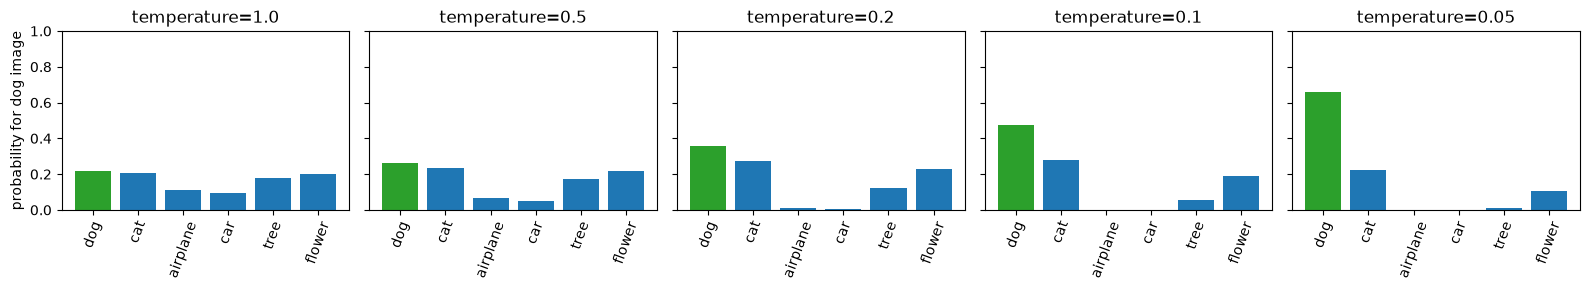

In [21]:
temperatures = (1.0, 0.5, 0.2, 0.1, 0.05)
probabilities_by_temperature = []

for temperature in temperatures:
    # apply softmax to the first image's scaled similarities.
    probabilities = F.softmax(similarities[0] / temperature, dim=0)
    probabilities_by_temperature.append(probabilities)

probability_matrix = torch.stack(probabilities_by_temperature)
torch.testing.assert_close(probability_matrix.sum(dim=1), torch.ones(len(temperatures)))

fig, axes = plt.subplots(1, len(temperatures), figsize=(16, 3), sharey=True)
for axis, temperature, probabilities in zip(axes, temperatures, probability_matrix):
    colors = ["tab:green" if index == 0 else "tab:blue" for index in range(NUMBER_ITEMS)]
    axis.bar(range(NUMBER_ITEMS), probabilities.numpy(), color=colors)
    axis.set_xticks(range(NUMBER_ITEMS), ITEM_NAMES, rotation=70)
    axis.set_title(f"temperature={temperature}")
    axis.set_ylim(0, 1)
axes[0].set_ylabel("probability for dog image")
plt.tight_layout()
plt.show()

## 7. What the loss changes

A real model updates both encoders. Here the image and text vectors themselves are trainable so the geometry is easy to observe.

The objective should increase diagonal similarity relative to competing off-diagonal values. It does not require every nonmatching pair to reach similarity $-1$; it requires each correct match to win its row and column.

### Exercise 7 — Optimize the paired embeddings

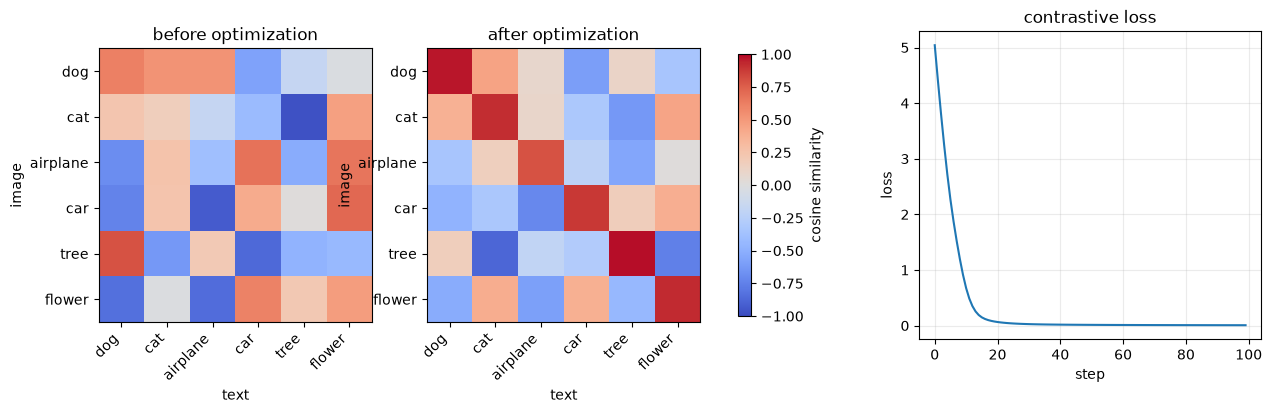

mean diagonal similarity: 0.134 -> 0.914


In [23]:
torch.manual_seed(SEED)
learned_images = torch.nn.Parameter(torch.randn(NUMBER_ITEMS, EMBEDDING_DIM))
learned_texts = torch.nn.Parameter(torch.randn(NUMBER_ITEMS, EMBEDDING_DIM))
optimizer = torch.optim.Adam((learned_images, learned_texts), lr=3e-2)

with torch.no_grad():
    similarities_before = (
        F.normalize(learned_images, dim=1)
        @ F.normalize(learned_texts, dim=1).T
    ).clone()

optimization_losses = []
for step in range(100):
    # calculate loss, reset gradients, backpropagate, and update both tensors.
    loss = clip_contrastive_loss(learned_images, learned_texts, TEMPERATURE)[0]
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    optimization_losses.append(loss.item())

with torch.no_grad():
    _, similarities_after = clip_contrastive_loss(
        learned_images, learned_texts, TEMPERATURE
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, matrix, title in zip(
    axes[:2],
    (similarities_before, similarities_after),
    ("before optimization", "after optimization"),
):
    heatmap = axis.imshow(matrix.numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    axis.set_xticks(range(NUMBER_ITEMS), ITEM_NAMES, rotation=45, ha="right")
    axis.set_yticks(range(NUMBER_ITEMS), ITEM_NAMES)
    axis.set(title=title, xlabel="text", ylabel="image")
axes[2].plot(optimization_losses)
axes[2].set(title="contrastive loss", xlabel="step", ylabel="loss")
axes[2].grid(alpha=0.25)
fig.colorbar(heatmap, ax=axes[:2], shrink=0.85, label="cosine similarity")
plt.show()

diagonal_before = similarities_before.diag().mean()
diagonal_after = similarities_after.diag().mean()
print(f"mean diagonal similarity: {diagonal_before:.3f} -> {diagonal_after:.3f}")

## 8. The same space supports retrieval in both directions

- Image-to-text retrieval sorts one matrix row.
- Text-to-image retrieval sorts one matrix column.

Dot-product embeddings scale well because candidate vectors can be encoded and indexed in advance.

### Exercise 8 — Retrieve the top candidates

Return indices in descending similarity order for either direction.

In [24]:
def retrieve_top_k(similarity_matrix, query_index, k, *, direction):
    """Return top candidate indices for one image or text query."""
    if direction == "image_to_text":
        # select the query row.
        query_scores = similarity_matrix[query_index]
    elif direction == "text_to_image":
        # select the query column.
        query_scores = similarity_matrix[:, query_index]
    else:
        raise ValueError("unknown retrieval direction")
    # return indices of the k largest scores in descending order.
    return torch.topk(query_scores, k=k).indices.tolist()


for query_index, query_name in enumerate(ITEM_NAMES):
    text_matches = retrieve_top_k(
        similarities_after, query_index, 3, direction="image_to_text"
    )
    image_matches = retrieve_top_k(
        similarities_after, query_index, 3, direction="text_to_image"
    )
    print(
        f"{query_name:>8} image -> {[ITEM_NAMES[i] for i in text_matches]} | "
        f"{query_name:>8} text -> {[ITEM_NAMES[i] for i in image_matches]}"
    )

     dog image -> ['dog', 'cat', 'tree'] |      dog text -> ['dog', 'cat', 'tree']
     cat image -> ['cat', 'flower', 'dog'] |      cat text -> ['cat', 'dog', 'flower']
airplane image -> ['airplane', 'cat', 'flower'] | airplane text -> ['airplane', 'cat', 'dog']
     car image -> ['car', 'flower', 'tree'] |      car text -> ['car', 'flower', 'airplane']
    tree image -> ['tree', 'dog', 'airplane'] |     tree text -> ['tree', 'car', 'dog']
  flower image -> ['flower', 'cat', 'car'] |   flower text -> ['flower', 'cat', 'car']


## 9. What the simple objective assumes

For each pair, the other $N-1$ batch items become negatives. Larger, more diverse batches provide harder comparisons and more signal, but this creates limitations.

### False negatives

Two captions may both describe the same image even if only one is the recorded positive. For example, “a dog running” and “an animal outdoors” may both be valid. The one-positive-per-row objective can treat a valid alternative as negative.

### Fine-grained and compositional concepts

A batch may associate mugs and grass with words without containing the careful contrasts needed to distinguish “a mug in grass” from “grass in a mug.” Data quality and deliberate coverage matter as much as raw quantity.

### Alignment is not caption generation

CLIP scores compatibility between complete image and text representations; it does not autoregressively predict text tokens. CoCa adds a text decoder and captioning loss, combining contrastive alignment with generation.

Related notes:

- [Zero-shot classification and prompt ensembling](../notes/16-vision-language/zero-shot-classification-and-prompt-ensembling.md)
- [CLIP limitations and data quality](../notes/16-vision-language/clip-limitations-and-data-quality.md)

## Reflection

1. Why must the image and text encoders produce the same embedding width?

   **Answer:** Their feature dimensions must match for an image vector and a text vector to have a valid dot product.

2. Why are embeddings normalized before their dot product?

   **Answer:** Normalization makes the dot product depend only on vector direction rather than magnitude, turning it into cosine similarity.

3. What does one row of the similarity matrix represent?

   **Answer:** It contains the similarities between one image query and every text candidate in the batch.

4. Why is the expected positive match on the diagonal?

   **Answer:** The paired batch is arranged so image $i$ and text $i$ describe the same item, placing known positive pairs at $S_{ii}$.

5. Why does CLIP calculate loss in both directions?

   **Answer:** Image-to-text loss asks every image to retrieve its text, while text-to-image loss asks every text to retrieve its image. The two directions normalize different axes and can have different competitors and losses.

6. What does decreasing temperature change, and what remains unchanged?

   **Answer:** Decreasing temperature sharpens the softmax, increasing confidence in the highest-scoring candidates and changing gradient scale. It does not change the ordering of the similarities or which candidate ranks first.

7. Why can another correct description become a false negative?

   **Answer:** The basic objective designates only the paired item as positive and treats every other batch item as negative, even if another caption is also semantically valid.

8. Why is CLIP alignment different from image caption generation?

   **Answer:** CLIP scores compatibility between complete image and text embeddings. Caption generation instead predicts a sequence of text tokens autoregressively.